# Loss of Specific Core Species (Recalled Species)

Core loss (core species > 80% seasonal prevalence making up a low % of reads) gives a reproducible DE signal: chloroplast, translation and ribosome genes up, and stress, senescence and defense genes down (`core_loss_group_size_sweep_de.ipynb`). This notebook asks which core species drive it.

1. ***Sphingomonas* depletion.** *Sphingomonas* sp000786205 is the core species that accounts for most of the core loss (37% of the gap at n = 120). Plants depleted for it are compared with the rest in several ways:
   - **absolute ranking** on relative abundance (lowest `n` plants), as in the core-loss sweep
   - **per unit of plant DNA**: relative abundance × bacterial load (`ham16s`, 16S reads per host-gene read), which separates true loss of *Sphingomonas* from dilution by other bacteria
   - **within timepoint** (lowest 15% by within-timepoint z-score), on both scales
   - all 5 core *Sphingomonas* species combined
2. **Depletion of each core species individually** (40 species): the lowest 15% within timepoint, as fitted in `dysbiosis_definition_screen.ipynb` (reused from its cache), compared with the overall core-loss DE.
3. **Rare excess, 20 dysbiotic plants, rare = < 20% prevalence** (the small group that showed a hint of higher defense), at the table's floor and at the minimum abundances from `rare_core_min_abundance_double_sweep_de.ipynb`, compared with the overall DE.

**Reference ("overall") DE signals:**
- core loss, absolute ranking, n = 115 (`core_loss_prev0.8_n115`, 1,211 genes, the peak of the sweep)
- the 173 robust core-loss genes (significant in at least half of the group sizes from 40 to 135)
- rare excess < 30% at a 0.5% minimum abundance, n = 100 (1,305 genes)

**Comparing two DE results:** overlap of significant genes, and the Spearman correlation of log2 fold changes across all tested genes. The correlation shows whether two groupings shift expression the same way even when one has few significant genes.

All DESeq2 runs use `~timepoint + group`, with the same samples and gene filters as before. New fits are cached in `Generated_data/core_species_depletion_recalled_species/`.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import contextlib
import io
from pathlib import Path
import statsmodels.formula.api as smf
from scipy.stats import zscore
import pydeseq2.default_inference
import pydeseq2.ds
import pydeseq2.dds

from scipy.stats import spearmanr
import Go_tools

###Define Thresholds
target_species = "s__Sphingomonas_L_486704 sp000786205"
core_prevalence_threshold = 0.8
absolute_group_sizes = [20, 40, 60, 80, 100, 120]
within_timepoint_fraction = 0.15  # as in the definition screen
log_pseudocount = 0.05
expressed_gene_reads_threshold = 2000
number_of_samples_expressed_in_threshold = 21
n_cpus = 10
generated = Path("/Users/michael/Data/Luke_terrace_experiment/General_data/Generated_data")
results_dir = generated / "core_species_depletion_recalled_species"
sweep_dir = generated / "dysbiosis_threshold_sweep_recalled_species"
screen_dir = generated / "dysbiosis_definition_screen_recalled_species"

In [2]:
transcriptome = pd.read_csv(
    "/Users/michael/Data/Luke_terrace_experiment/General_data/plate1_5_tpm_normalized.csv",
    index_col=0,
)
rows_to_drop_expression_data = [
    "A2450525897_n01_undetermined",
    "A2449446903_n01_undetermined",
    "B250508004_n01_undetermined",
    "B2449500127_n01_undetermined",
]
transcriptome = transcriptome.drop(index=rows_to_drop_expression_data)
transcriptome = transcriptome.sort_index()
metadata = pd.read_csv(
    "/Users/michael/Data/Luke_terrace_experiment/General_data/Plates_1_to_5_metadata_merged_luke.csv",
    index_col=0,
)
raw_transcriptome = pd.read_csv(
    "/Users/michael/Data/Luke_terrace_experiment/General_data/plate1_5_for_norm.csv",
    index_col=0,
)

## Get plate 5 samples and remove what they replaced from the metadata to avoid duplicates
plate_5_replacements = metadata.loc[metadata["rnaprepplate"] == "LICRNA_05"]
non_plate_5_samples = metadata.loc[metadata["rnaprepplate"] != "LICRNA_05"]
replaced_samples = non_plate_5_samples.loc[
    non_plate_5_samples["sampID"].isin(plate_5_replacements["sampID"])
]
trimmed_metadata = metadata.drop(index=replaced_samples.index)
### For remaining duplicated sampIDs, drop the transcriptome with fewer total reads
double_duplicates = (
    trimmed_metadata.loc[trimmed_metadata.duplicated(subset="sampID", keep=False)]
    .sort_values(by="Total Reads")
    .drop_duplicates(subset="sampID", keep="first")
)
trimmed_metadata = trimmed_metadata.drop(index=double_duplicates.index)
### Drop failed libraries with too few reads (e.g. LIC162 has 66 total reads)
min_total_reads = 250_000
low_read_samples = trimmed_metadata.index[trimmed_metadata["Total Reads"] < min_total_reads]
trimmed_metadata = trimmed_metadata.drop(index=low_read_samples)
print(f"Dropped {len(low_read_samples)} transcriptomes with < {min_total_reads:,} total reads")
trimmed_transcriptome = transcriptome.loc[trimmed_metadata.index]
trimmed_raw_transcriptome = raw_transcriptome.loc[trimmed_metadata.index]
print("Transcriptomes after removing replicates:", len(trimmed_metadata))

# Same gene filters as the dysbiosis DE notebook
cleaned_raw_transcriptome = trimmed_raw_transcriptome.loc[
    :, trimmed_raw_transcriptome.sum() > expressed_gene_reads_threshold
]
cleaned_raw_transcriptome = cleaned_raw_transcriptome.loc[
    :, (cleaned_raw_transcriptome > 1).sum() > number_of_samples_expressed_in_threshold
]
print("Genes kept for DESeq2:", cleaned_raw_transcriptome.shape[1])

# Defense score: only used to describe the groups, never to define them
defense_gene_list = pd.read_csv(
    "/Users/michael/Data/Luke_terrace_experiment/General_data/Generated_data/load_correlated_genes_union_GO_and_FLG_plates_1_to_5.csv"
)
defense_genes = set(defense_gene_list["gene"])
transcriptome_in_defense_gene_list = trimmed_transcriptome.loc[
    :, trimmed_transcriptome.columns.isin(defense_genes)
]
trimmed_metadata["Defense Score"] = transcriptome_in_defense_gene_list.apply(zscore).sum(
    axis=1
) / len(defense_gene_list)

# Old species-level DE genes (59, plates 1-5), for overlap
old_de_genes = set(
    pd.read_csv(
        "/Users/michael/Data/Luke_terrace_experiment/General_data/Junk_data/large_deseq_gene_list_all_plates.csv",
        header=None,
    )[0]
)

Dropped 6 transcriptomes with < 250,000 total reads
Transcriptomes after removing replicates: 426


Genes kept for DESeq2: 18032


## Species abundance

In [3]:
### Recalled species table. Species under 0.05% of a sample (AbundR == 0) are
### dropped, as in the recalled-genera table
min_abundR = 1
### Plant samples missing from the recalled-genera table (LIC148, LIC162, LIC584 have
### < 1,600 16S reads; LIC577 unknown). Kept for now: see to_revisit.txt
samples_to_drop = []  # ["LIC148", "LIC162", "LIC577", "LIC584"]
microbiome_abundance = pd.read_csv(
    "/Users/michael/Data/Luke_terrace_experiment/Oct_2026_recalled_species/lic16s_species_relabund.csv"
)
microbiome_abundance = microbiome_abundance.loc[
    (microbiome_abundance["AbundR"] >= min_abundR)
    & ~microbiome_abundance["Sample"].isin(samples_to_drop)
].copy()
# No seascirc column in the species table: circadian timepoints start with "c"
microbiome_abundance["seascirc"] = np.where(
    microbiome_abundance["timepoint"].str.startswith("c"), "circadian", "seasonal"
)
plant_microbiome = microbiome_abundance.loc[microbiome_abundance["sample.type"] == "plant"]

# Sample x species abundance as % of each sample's reads (absent species = 0)
species_abundance_matrix = pd.pivot_table(
    plant_microbiome, values="Abundance", index="Sample", columns="Species", aggfunc="sum", fill_value=0
)
species_abundance_matrix = species_abundance_matrix.div(species_abundance_matrix.sum(axis=1), axis=0) * 100
seasonal_samples = plant_microbiome.loc[plant_microbiome["seascirc"] == "seasonal", "Sample"].unique()
seasonal_prevalence = (species_abundance_matrix.loc[seasonal_samples] > 0).mean()

# Transcriptome samples, all with a microbiome profile
de_samples = trimmed_metadata.index[trimmed_metadata["sampID"].isin(species_abundance_matrix.index)]
print("Transcriptomes with a microbiome profile:", len(de_samples), "of", len(trimmed_metadata))
sample_species = species_abundance_matrix.loc[trimmed_metadata.loc[de_samples, "sampID"]].set_index(de_samples)

Transcriptomes with a microbiome profile: 426 of 426


In [4]:
inference = pydeseq2.default_inference.DefaultInference(n_cpus=n_cpus)
de_counts = cleaned_raw_transcriptome.loc[de_samples]
results_dir.mkdir(parents=True, exist_ok=True)


def run_deseq(run_id, high_samples):
    """DESeq2 ~timepoint + group (High vs Low) on all DE samples. Results are cached
    in results_dir, so a re-run only fits groupings it hasn't seen."""
    cache = results_dir / f"{run_id}.csv"
    if cache.exists():
        return pd.read_csv(cache, index_col=0)
    design_metadata = pd.DataFrame(
        {
            "timepoint": trimmed_metadata.loc[de_samples, "timepoint"],
            "group": np.where(de_samples.isin(high_samples), "High", "Low"),
        },
        index=de_samples,
    )
    with contextlib.redirect_stdout(io.StringIO()), contextlib.redirect_stderr(io.StringIO()):
        dds = pydeseq2.dds.DeseqDataSet(
            counts=de_counts,
            metadata=design_metadata,
            design="~timepoint+group",
            refit_cooks=True,
            inference=inference,
            quiet=True,
        )
        dds.deseq2()
        stats = pydeseq2.ds.DeseqStats(
            dds, contrast=["group", "High", "Low"], inference=inference, quiet=True
        )
        stats.summary()
    results = stats.results_df
    results.to_csv(cache)
    return results


def summarise_run(results, high_samples):
    """DE gene counts, plus how the group's defense score compares (timepoint-adjusted)."""
    significant = results.loc[results["padj"] < 0.05]
    defense_df = trimmed_metadata.loc[de_samples, ["timepoint", "Defense Score"]].assign(
        high=de_samples.isin(high_samples).astype(int)
    )
    fit = smf.ols("Q('Defense Score') ~ C(timepoint) + high", data=defense_df).fit()
    return {
        "n High": int(defense_df["high"].sum()),
        "significant (padj < 0.05)": len(significant),
        "up": int((significant["log2FoldChange"] > 0).sum()),
        "down": int((significant["log2FoldChange"] < 0).sum()),
        "significant, |LFC| > 1": int((significant["log2FoldChange"].abs() > 1).sum()),
        "min padj": results["padj"].min(),
        "defense genes among significant": len(set(significant.index) & defense_genes),
        "old DE genes among significant": len(set(significant.index) & old_de_genes),
        "defense score diff (timepoint-adjusted)": fit.params["high"],
        "defense score diff p": fit.pvalues["high"],
    }

In [5]:
timepoint = trimmed_metadata.loc[de_samples, "timepoint"]
defense_score = trimmed_metadata.loc[de_samples, "Defense Score"]
load_table = pd.read_csv("/Users/michael/Data/Luke_terrace_experiment/Microbiome/lic2024_ham_16S_ITS.csv", index_col=0)
bacterial_load = trimmed_metadata.loc[de_samples, "sampID"].map(load_table["ham16s"])
core_species = seasonal_prevalence.index[seasonal_prevalence > core_prevalence_threshold]
log_species = np.log10(sample_species + log_pseudocount)


def fit_cached(cache_dir, run_id, high_samples):
    """run_deseq with the cache in another folder (results_dir is a global used by run_deseq)."""
    global results_dir
    own_dir = results_dir
    results_dir = Path(cache_dir)
    try:
        return run_deseq(run_id, high_samples)
    finally:
        results_dir = own_dir


def within_timepoint_z(score):
    """Identical to the definition screen, so its cached groups are reproduced exactly."""
    score = score.reindex(de_samples).astype(float)
    grouped = score.groupby(timepoint)
    z = (score - grouped.transform("mean")) / grouped.transform("std")
    return z.where(score.notna()).fillna(0).where(score.notna())


def lowest_within_timepoint(values, fraction=within_timepoint_fraction):
    z = within_timepoint_z(-values)
    return z.dropna().sort_values(ascending=False).index[: round(fraction * len(de_samples))]


def defense_gene_counts(results):
    defense_results = results.loc[results.index.isin(defense_genes)]
    significant = defense_results["padj"] < 0.05
    return {
        "defense genes up": int((significant & (defense_results["log2FoldChange"] > 0)).sum()),
        "defense genes down": int((significant & (defense_results["log2FoldChange"] < 0)).sum()),
    }


# Reference DE signals
double_sweep = pd.read_csv(sweep_dir / "double_sweep_deseq_summary.csv")
rare_reference_id = double_sweep.loc[
    (double_sweep["definition"] == "rare excess") & (double_sweep["min abundance (%)"] == 0.5)
    & (double_sweep["prevalence"] == 0.3) & (double_sweep["group size"] == 100), "fit_id"
].iloc[0]
references = {
    "core loss n=115": pd.read_csv(sweep_dir / "core_loss_prev0.8_n115.csv", index_col=0),
    "rare excess <30%, min 0.5%, n=100": pd.read_csv(sweep_dir / f"{rare_reference_id}.csv", index_col=0),
}
robust_core_loss_genes = pd.read_csv(sweep_dir / "core_loss_robust_genes.csv", index_col=0)
robust_up = set(robust_core_loss_genes.index[robust_core_loss_genes["median log2FC"] > 0])
robust_down = set(robust_core_loss_genes.index[robust_core_loss_genes["median log2FC"] < 0])


def compare_to_references(results):
    """Overlap and log2FC correlation of one DE result with the reference signals."""
    significant = set(results.index[results["padj"] < 0.05])
    up = set(results.index[(results["padj"] < 0.05) & (results["log2FoldChange"] > 0)])
    down = significant - up
    out = {
        "robust core-loss genes significant (same direction)": len((up & robust_up) | (down & robust_down)),
    }
    for name, reference in references.items():
        reference_significant = set(reference.index[reference["padj"] < 0.05])
        shared = reference.index.intersection(results.index)
        out[f"shared DE genes with {name}"] = len(significant & reference_significant)
        out[f"LFC rho with {name}"] = spearmanr(results.loc[shared, "log2FoldChange"], reference.loc[shared, "log2FoldChange"], nan_policy="omit")[0]
    return out


def go_enrichment(genes, background):
    with contextlib.redirect_stdout(io.StringIO()), contextlib.redirect_stderr(io.StringIO()):
        tables = Go_tools.generate_contigency_tables(go_annotations=go_term_matrix, gene_list=list(genes), use_background_genes=True, background_genes=background)
        results = Go_tools.multi_hypothesis_correct_fishers_exact(
            Go_tools.fishers_exact_on_contigency_tables(all_go_contigency_tables=tables, original_GO_term_panda=go_term_matrix)
        )
    return results.merge(go_term_names, left_index=True, right_index=True, how="left").sort_values("P_value")


go_term_matrix = pd.read_csv("/Users/michael/Data/Reference_data/Arabdidopsis_go_matrix_from_tair_gaf.csv", index_col=0)
go_term_names = pd.read_csv("/Users/michael/Data/Reference_data/goterm_names.csv", index_col=0)
background_genes = de_counts.columns.tolist()
print(f"Core species: {len(core_species)}")
for name, reference in references.items():
    print(f"{name}: {(reference['padj'] < 0.05).sum()} DE genes")
print(f"Robust core-loss genes: {len(robust_core_loss_genes)} ({len(robust_up)} up, {len(robust_down)} down)")

Core species: 40
core loss n=115: 1211 DE genes
rare excess <30%, min 0.5%, n=100: 1305 DE genes
Robust core-loss genes: 173 (93 up, 80 down)


## 1. *Sphingomonas* depletion

How *Sphingomonas* sp000786205 is distributed, as relative abundance and per unit of plant DNA, and how the two relate to its role in core loss.

Core Sphingomonas species: ['s__Sphingomonas_L_486704 panacisoli', 's__Sphingomonas_L_486704 sp000786205', 's__Sphingomonas_L_486704 sp001421805', 's__Sphingomonas_L_486704 sp001423845', 's__Sphingomonas_L_486704 taxi']
s__Sphingomonas_L_486704 sp000786205: prevalence 1.00, median 14.0% of reads
Share of core abundance: median 19%
Within-timepoint Spearman, relative abundance vs per-host amount: 0.91 | relative abundance vs total core abundance: 0.37


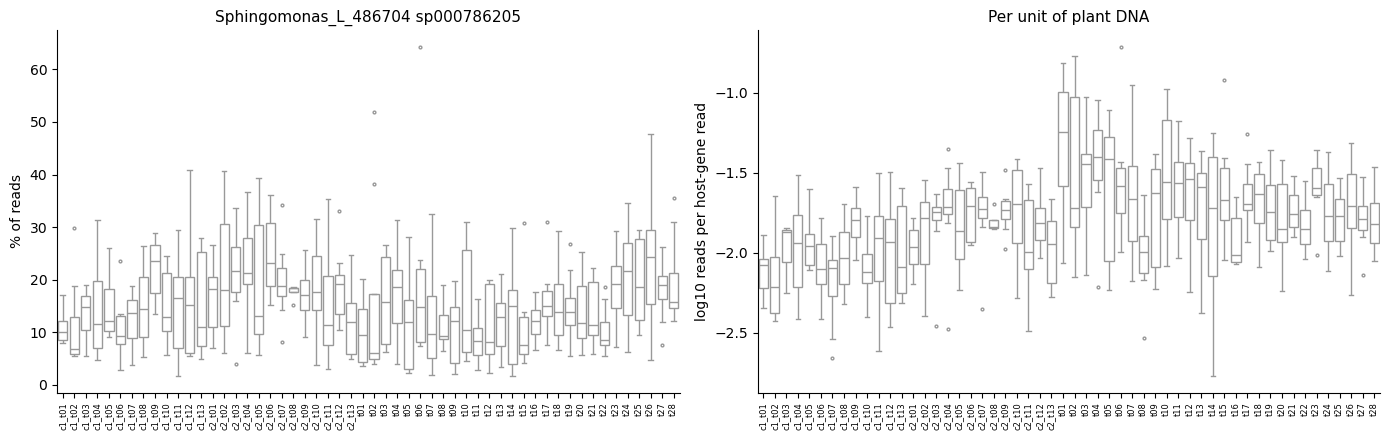

In [6]:
sphingomonas_relative = sample_species[target_species]
sphingomonas_per_host = (sphingomonas_relative + log_pseudocount) / 100 * bacterial_load  # 16S reads of this species per host-gene read (pseudocount for absences)
core_sphingomonas = [s for s in core_species if s.startswith("s__Sphingomonas")]
core_sphingomonas_relative = sample_species[core_sphingomonas].sum(axis=1)
core_abund = sample_species[core_species].sum(axis=1)
print(f"Core Sphingomonas species: {core_sphingomonas}")
print(f"{target_species}: prevalence {seasonal_prevalence[target_species]:.2f}, median {sphingomonas_relative.median():.1f}% of reads")
print(f"Share of core abundance: median {(sphingomonas_relative / core_abund).median():.0%}")
print(
    "Within-timepoint Spearman, relative abundance vs per-host amount:",
    round(spearmanr(within_timepoint_z(np.log10(sphingomonas_relative + log_pseudocount)), within_timepoint_z(np.log10(sphingomonas_per_host)), nan_policy="omit")[0], 2),
    "| relative abundance vs total core abundance:",
    round(spearmanr(within_timepoint_z(sphingomonas_relative), within_timepoint_z(core_abund))[0], 2),
)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
fig.patch.set_facecolor("white")
order = sorted(timepoint.unique())
sns.boxplot(x=timepoint, y=sphingomonas_relative, order=order, color="white", fliersize=2, ax=axes[0])
axes[0].set_ylabel("% of reads")
axes[0].set_title(target_species.replace("s__", ""), fontsize=11)
sns.boxplot(x=timepoint, y=np.log10(sphingomonas_per_host), order=order, color="white", fliersize=2, ax=axes[1])
axes[1].set_ylabel("log10 reads per host-gene read")
axes[1].set_title("Per unit of plant DNA", fontsize=11)
for ax in axes:
    ax.tick_params(axis="x", rotation=90, labelsize=6)
    ax.set_xlabel("")
    sns.despine(ax=ax)
plt.tight_layout()

In [7]:
sphingomonas_groupings = []
for n in absolute_group_sizes:
    sphingomonas_groupings.append(("relative abundance, absolute", n, sphingomonas_relative.sort_values().index[:n], f"sphingomonas_relative_absolute_n{n}"))
    per_host = sphingomonas_per_host.dropna()
    sphingomonas_groupings.append(("per host DNA, absolute", n, per_host.sort_values().index[:n], f"sphingomonas_per_host_absolute_n{n}"))
sphingomonas_groupings += [
    ("relative abundance, within timepoint", None, lowest_within_timepoint(np.log10(sphingomonas_relative + log_pseudocount)), None),
    ("per host DNA, within timepoint", None, lowest_within_timepoint(np.log10(sphingomonas_per_host)), "sphingomonas_per_host_within_timepoint"),
    ("all core Sphingomonas, relative, within timepoint", None, lowest_within_timepoint(np.log10(core_sphingomonas_relative + log_pseudocount)), "core_sphingomonas_relative_within_timepoint"),
    ("all core Sphingomonas, relative, absolute", 60, core_sphingomonas_relative.sort_values().index[:60], "core_sphingomonas_relative_absolute_n60"),
    ("all core Sphingomonas, relative, absolute", 100, core_sphingomonas_relative.sort_values().index[:100], "core_sphingomonas_relative_absolute_n100"),
]

screen_summary = pd.read_csv(screen_dir / "screen_summary.csv")
screen_fit_id = screen_summary.set_index("run_id")["fit_id"]
sphingomonas_results = {}
rows = []
for definition, n, high_samples, run_id in sphingomonas_groupings:
    if run_id is None:  # the definition screen's within-timepoint depletion, from its cache
        cache_dir, fit_id = screen_dir / "fits", screen_fit_id[f"Species_depletion__{target_species.replace(' ', '_')}_top15"]
    else:
        cache_dir, fit_id = results_dir, run_id
    results = fit_cached(cache_dir, fit_id, high_samples)
    key = f"{definition}" + (f", n={n}" if n else "")
    sphingomonas_results[key] = (results, high_samples)
    rows.append(
        {
            "grouping": key,
            "median % Sphingomonas in group": sphingomonas_relative[high_samples].median(),
            "median core % in group": core_abund[high_samples].median(),
            "Nov-Dec plants in group": int(trimmed_metadata.loc[high_samples, "Sample Month"].isin(["November", "December"]).sum()),
            **summarise_run(results, high_samples),
            **defense_gene_counts(results),
            **compare_to_references(results),
        }
    )
sphingomonas_summary = pd.DataFrame(rows).set_index("grouping")
sphingomonas_summary.to_csv(results_dir / "sphingomonas_depletion_summary.csv")
sphingomonas_summary.drop(columns=["old DE genes among significant"]).round(3)

,median % Sphingomonas in group,median core % in group,Nov-Dec plants in group,n High,significant (padj < 0.05),up,down,"significant, |LFC| > 1",min padj,defense genes among significant,defense score diff (timepoint-adjusted),defense score diff p,defense genes up,defense genes down,robust core-loss genes significant (same direction),shared DE genes with core loss n=115,LFC rho with core loss n=115,"shared DE genes with rare excess <30%, min 0.5%, n=100","LFC rho with rare excess <30%, min 0.5%, n=100"
grouping,,,,,,,,,,,,,,,,,,,
"relative abundance, absolute, n=20",2.861,62.796,11,20,1,0,1,1,0.004,0,-0.065,0.543,0,0,0,0,0.352,0,0.336
"per host DNA, absolute, n=20",5.012,80.612,1,20,4,1,3,3,0.011,0,-0.021,0.845,0,0,0,1,0.333,1,0.301
"relative abundance, absolute, n=40",3.875,66.539,19,40,78,11,67,2,0.002,4,-0.113,0.147,1,3,10,40,0.549,35,0.527
"per host DNA, absolute, n=40",5.456,78.502,3,40,149,33,116,10,0.000,4,-0.050,0.514,1,3,14,61,0.499,71,0.482
"relative abundance, absolute, n=60",4.503,70.836,21,60,0,0,0,0,0.102,0,-0.036,0.575,0,0,0,0,0.423,0,0.416
"per host DNA, absolute, n=60",5.829,78.502,7,60,313,124,189,4,0.000,8,-0.067,0.308,3,5,31,152,0.540,166,0.531
"relative abundance, absolute, n=80",5.254,72.507,28,80,0,0,0,0,0.054,0,-0.040,0.492,0,0,0,0,0.434,0,0.442
"per host DNA, absolute, n=80",6.113,78.813,11,80,160,35,125,2,0.000,2,-0.052,0.384,1,1,17,78,0.506,80,0.526
"relative abundance, absolute, n=100",5.640,73.533,32,100,16,3,13,1,0.010,0,-0.069,0.191,0,0,1,9,0.464,8,0.491


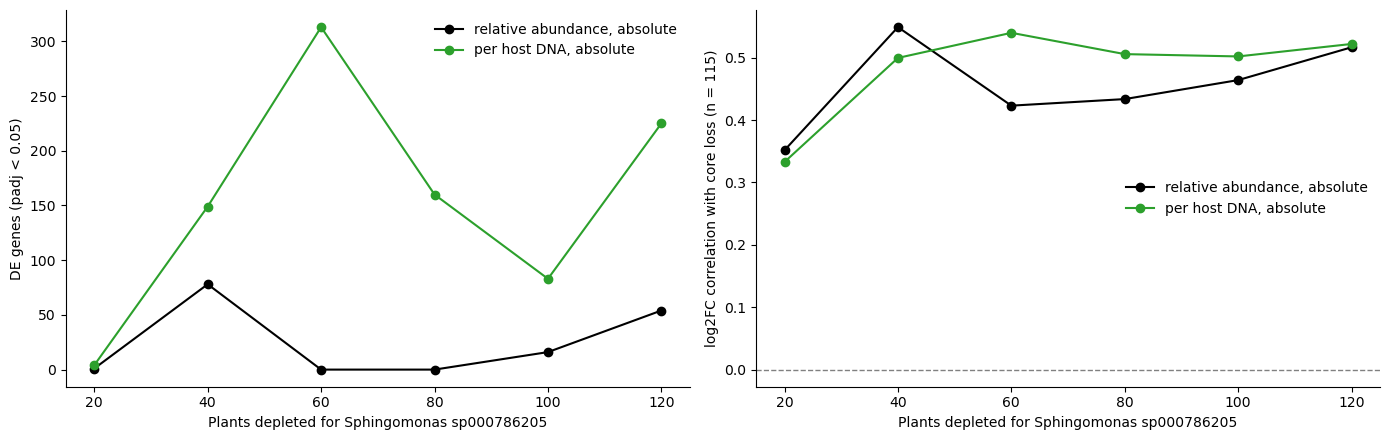

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
fig.patch.set_facecolor("white")
for scale, color in [("relative abundance, absolute", "black"), ("per host DNA, absolute", "tab:green")]:
    part = sphingomonas_summary.loc[sphingomonas_summary.index.str.startswith(scale)]
    sizes = [int(i.split("n=")[1]) for i in part.index]
    axes[0].plot(sizes, part["significant (padj < 0.05)"], marker="o", color=color, label=scale)
    axes[1].plot(sizes, part["LFC rho with core loss n=115"], marker="o", color=color, label=scale)
axes[0].set_ylabel("DE genes (padj < 0.05)")
axes[1].set_ylabel("log2FC correlation with core loss (n = 115)")
axes[1].axhline(0, color="gray", linestyle="dashed", linewidth=1)
for ax in axes:
    ax.set_xlabel("Plants depleted for Sphingomonas sp000786205")
    ax.legend(frameon=False)
    sns.despine(ax=ax)
plt.tight_layout()

In [9]:
# GO enrichment for the Sphingomonas grouping with the most DE genes
best_key = sphingomonas_summary["significant (padj < 0.05)"].idxmax()
best_results = sphingomonas_results[best_key][0]
significant = best_results.loc[best_results["padj"] < 0.05]
print(f"{best_key}: {len(significant)} DE genes")
for label, genes in [("up in depleted plants", significant.index[significant["log2FoldChange"] > 0]), ("down", significant.index[significant["log2FoldChange"] < 0])]:
    print(f"\n=== {label}: {len(genes)} genes ===")
    if len(genes) >= 10:
        display(go_enrichment(genes, background_genes).head(12)[["P_value", "x"]])

per host DNA, absolute, n=60: 313 DE genes

=== up in depleted plants: 124 genes ===


,P_value,x
GO:0009507,3.415926e-34,chloroplast
GO:0009570,1.580935e-32,chloroplast stroma
GO:0009941,1.848804e-32,chloroplast envelope
GO:0009579,1.075362e-15,thylakoid
GO:0009535,2.587910e-12,chloroplast thylakoid membrane
GO:0009536,3.285887e-12,plastid
GO:0009534,7.797357e-11,chloroplast thylakoid
GO:0010319,8.479797e-08,stromule
GO:0003729,8.479797e-08,mRNA binding
GO:0005829,7.103579e-05,cytosol



=== down: 189 genes ===


,P_value,x
GO:0050832,9.063998e-09,defense response to fungus
GO:0042742,1.129714e-05,defense response to bacterium
GO:0009751,1.257517e-04,response to salicylic acid
GO:0043295,7.066396e-03,glutathione binding
GO:0009753,7.066396e-03,response to jasmonic acid
GO:0009723,9.179450e-03,response to ethylene
GO:0009617,9.533452e-03,response to bacterium
GO:0006952,9.533452e-03,defense response
GO:0006979,9.533452e-03,response to oxidative stress
GO:0005886,9.533452e-03,plasma membrane


## 2. Depletion of each core species

The lowest 15% of plants within each timepoint for each of the 40 core species (fits from the definition screen). For each: DE genes, defense, overlap and fold-change correlation with the overall core-loss DE, and how much that species contributes to overall core loss (its abundance gap between the core-loss group at n = 115 and the rest).

In [10]:
core_loss_group = core_abund.sort_values().index[:115]
in_core_loss = de_samples.isin(core_loss_group)
contribution = sample_species.loc[~in_core_loss, core_species].mean() - sample_species.loc[in_core_loss, core_species].mean()

screen_rows = screen_summary.set_index("run_id")
species_results = {}
rows = []
for species in core_species:
    run_id = "".join(c if c.isalnum() else "_" for c in f"Species depletion: {species}_top15").strip("_")[:120]
    high_samples = lowest_within_timepoint(log_species[species])
    results = fit_cached(screen_dir / "fits", screen_fit_id[run_id], high_samples)
    species_results[species] = results
    summary = summarise_run(results, high_samples)
    rows.append(
        {
            "species": species,
            "prevalence": seasonal_prevalence[species],
            "mean %": sample_species[species].mean(),
            "share of core loss (n=115)": contribution[species] / contribution.sum(),
            "group check (defense diff vs screen)": summary["defense score diff (timepoint-adjusted)"] - screen_rows.loc[run_id, "defense diff"],
            **summary,
            **defense_gene_counts(results),
            **compare_to_references(results),
        }
    )
species_depletion = pd.DataFrame(rows).set_index("species")
assert species_depletion["group check (defense diff vs screen)"].abs().max() < 1e-6, "groups differ from the screen's cached fits"
species_depletion = species_depletion.drop(columns=["group check (defense diff vs screen)", "old DE genes among significant"])
species_depletion.to_csv(results_dir / "core_species_depletion_summary.csv")
species_depletion.sort_values("LFC rho with core loss n=115", ascending=False).round(3)

,prevalence,mean %,share of core loss (n=115),n High,significant (padj < 0.05),up,down,"significant, |LFC| > 1",min padj,defense genes among significant,defense score diff (timepoint-adjusted),defense score diff p,defense genes up,defense genes down,robust core-loss genes significant (same direction),shared DE genes with core loss n=115,LFC rho with core loss n=115,"shared DE genes with rare excess <30%, min 0.5%, n=100","LFC rho with rare excess <30%, min 0.5%, n=100"
species,,,,,,,,,,,,,,,,,,,
s__Klenkia sp001424455,1.000,3.035,0.001,64,1672,847,825,6,0.000,21,-0.184,0.002,9,12,99,554,0.523,595,0.523
s__Sphingomonas_L_486704 sp001423845,0.911,1.163,0.045,64,1,1,0,0,0.007,0,-0.024,0.684,0,0,0,1,0.441,0,0.436
s__Telluria agri,0.821,0.496,-0.001,64,44,30,14,2,0.008,0,-0.053,0.368,0,0,7,21,0.381,28,0.399
s__Sphingomonas_L_486704 sp000786205,1.000,15.607,0.366,64,1,0,1,0,0.026,0,-0.004,0.949,0,0,0,0,0.350,0,0.365
s__Nakamurella deserti,0.911,0.442,0.011,64,279,183,96,4,0.002,2,-0.028,0.634,1,1,20,92,0.340,95,0.344
s__Nocardioides_A_392796 sp001428125,0.978,0.746,-0.004,64,0,0,0,0,0.113,0,-0.100,0.086,0,0,0,0,0.336,0,0.335
s__Massilia atriviolacea,1.000,4.289,-0.013,64,4,2,2,1,0.036,0,-0.088,0.135,0,0,0,0,0.316,0,0.300
s__Aureimonas_A_501549 sp001424685,0.933,0.520,0.006,64,4,1,3,3,0.014,0,-0.104,0.078,0,0,0,0,0.304,1,0.295
s__Friedmanniella luteola,0.862,0.250,-0.012,64,0,0,0,0,0.170,0,-0.087,0.160,0,0,0,0,0.293,0,0.301


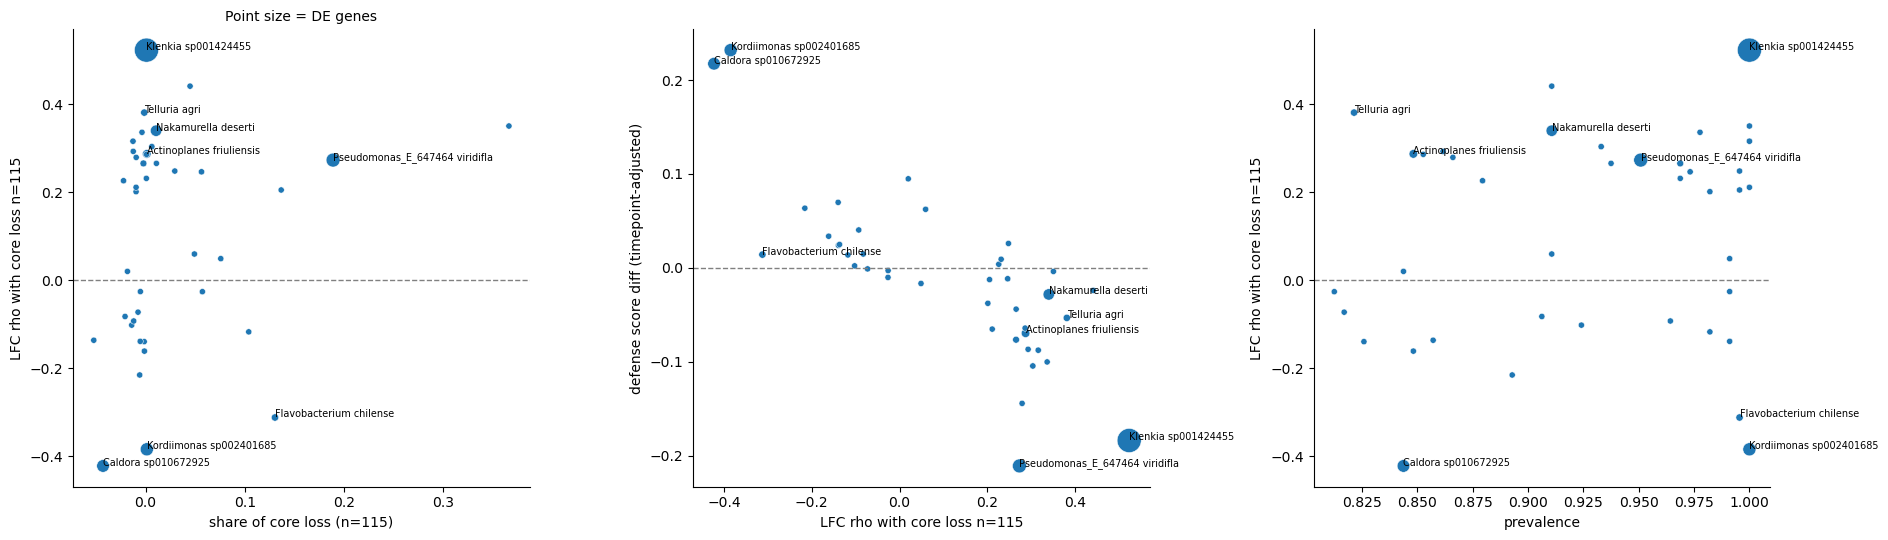

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(19, 5.5))
fig.patch.set_facecolor("white")
plot_df = species_depletion.assign(label=species_depletion.index.str.replace("s__", "").str.replace("_486704", "").str[:30])
sns.scatterplot(data=plot_df, x="share of core loss (n=115)", y="LFC rho with core loss n=115", size="significant (padj < 0.05)", sizes=(20, 300), ax=axes[0], legend=False)
sns.scatterplot(data=plot_df, x="LFC rho with core loss n=115", y="defense score diff (timepoint-adjusted)", size="significant (padj < 0.05)", sizes=(20, 300), ax=axes[1], legend=False)
sns.scatterplot(data=plot_df, x="prevalence", y="LFC rho with core loss n=115", size="significant (padj < 0.05)", sizes=(20, 300), ax=axes[2], legend=False)
for ax, (x, y) in zip(axes, [("share of core loss (n=115)", "LFC rho with core loss n=115"), ("LFC rho with core loss n=115", "defense score diff (timepoint-adjusted)"), ("prevalence", "LFC rho with core loss n=115")]):
    for _, row in plot_df.sort_values("significant (padj < 0.05)", ascending=False).head(8).iterrows():
        ax.text(row[x], row[y], row["label"], fontsize=7)
    ax.axhline(0, color="gray", linestyle="dashed", linewidth=1)
    sns.despine(ax=ax)
axes[0].set_title("Point size = DE genes", fontsize=10)
plt.tight_layout()

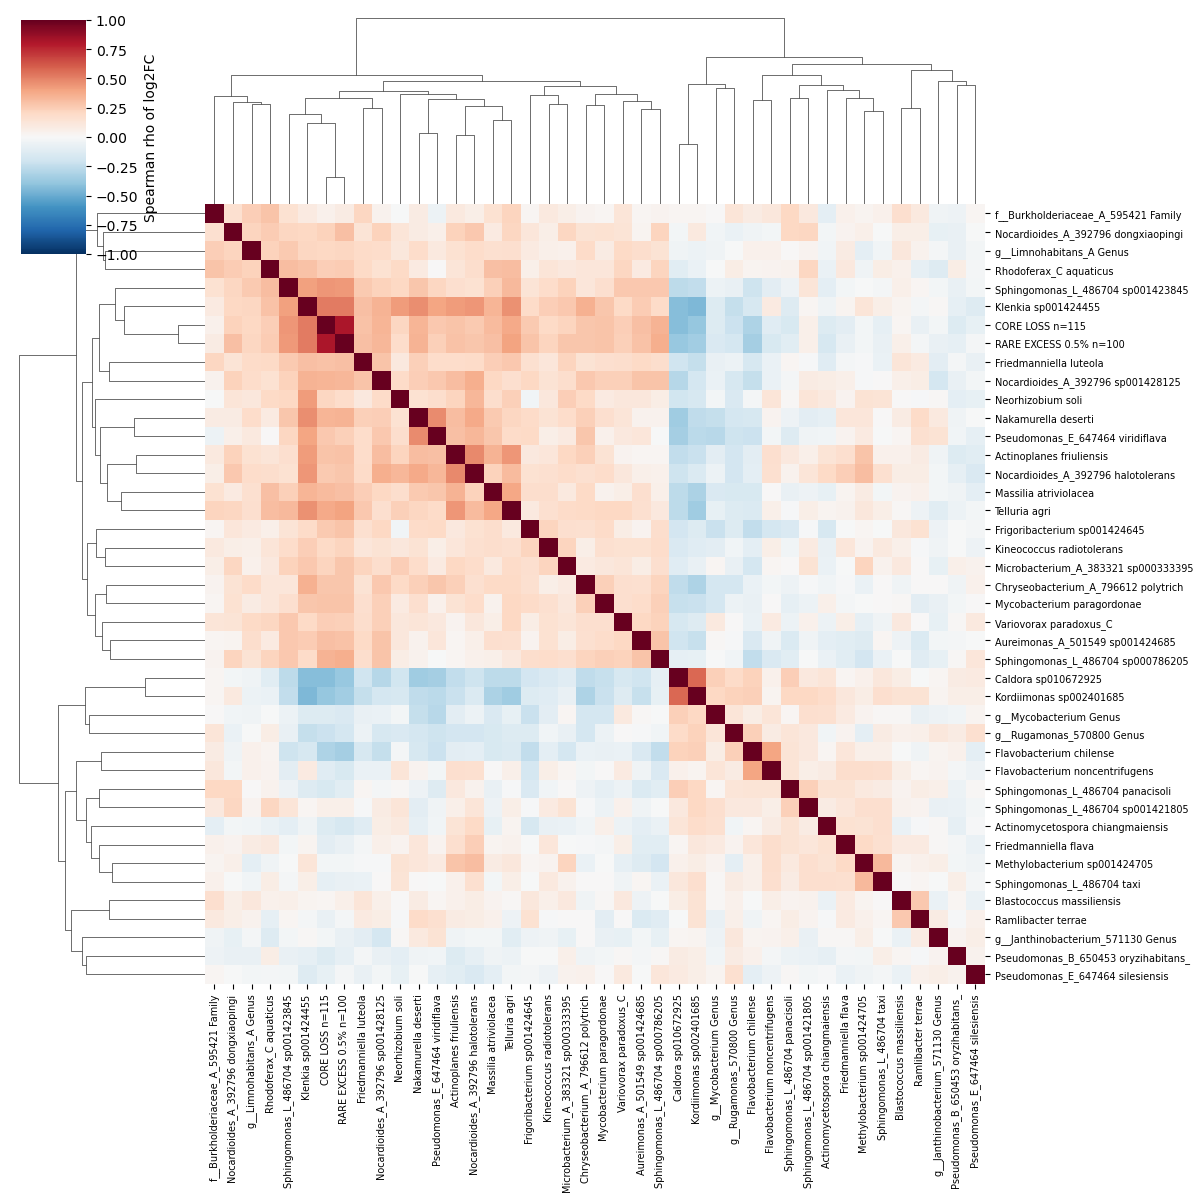

In [12]:
# Do different species' depletions shift expression the same way? Clustered log2FC correlations
lfc = pd.DataFrame({s.replace("s__", "")[:35]: r["log2FoldChange"] for s, r in species_results.items()})
lfc["CORE LOSS n=115"] = references["core loss n=115"]["log2FoldChange"]
lfc["RARE EXCESS 0.5% n=100"] = references["rare excess <30%, min 0.5%, n=100"]["log2FoldChange"]
lfc_correlation = lfc.corr(method="spearman")
g = sns.clustermap(lfc_correlation, cmap="RdBu_r", center=0, vmin=-1, vmax=1, figsize=(13, 13), xticklabels=True, yticklabels=True, cbar_kws={"label": "Spearman rho of log2FC"})
g.ax_heatmap.tick_params(labelsize=7)

In [13]:
# How many core-loss DE genes does at least one single-species depletion recover?
core_loss_significant = set(references["core loss n=115"].index[references["core loss n=115"]["padj"] < 0.05])
recovered = pd.Series(
    {s: len(core_loss_significant & set(r.index[r["padj"] < 0.05])) for s, r in species_results.items()}
).sort_values(ascending=False)
any_species = set().union(*[set(r.index[r["padj"] < 0.05]) for r in species_results.values()])
print(f"Core-loss (n=115) DE genes: {len(core_loss_significant)}; significant in at least one single-species depletion: {len(core_loss_significant & any_species)}")
print(f"Robust core-loss genes significant in at least one single-species depletion: {len(set(robust_core_loss_genes.index) & any_species)} of {len(robust_core_loss_genes)}")
recovered.head(10)

Core-loss (n=115) DE genes: 1211; significant in at least one single-species depletion: 638
Robust core-loss genes significant in at least one single-species depletion: 108 of 173


s__Klenkia sp001424455                   554
s__Kordiimonas sp002401685               177
s__Caldora sp010672925                   154
s__Pseudomonas_E_647464 viridiflava      126
s__Nakamurella deserti                    92
s__Actinoplanes friuliensis               54
s__Telluria agri                          21
s__Nocardioides_A_392796 halotolerans     13
s__Flavobacterium chilense                10
s__Sphingomonas_L_486704 sp001423845       1
dtype: int64

## 3. Rare excess, 20 plants, rare = < 20% prevalence

The small rare-excess group with a hint of higher defense, at the table's floor (original sweep) and at each minimum abundance (double sweep). Fits come from the sweep caches.

In [14]:
rare_rows = []
rare_results = {}
for _, row in double_sweep.loc[
    (double_sweep["definition"] == "rare excess") & (double_sweep["prevalence"] == 0.2) & (double_sweep["group size"] == 20)
].iterrows():
    results = pd.read_csv(sweep_dir / f"{row['fit_id']}.csv", index_col=0)
    label = "floor (0.05%)" if row["min abundance (%)"] == 0 else f"min {row['min abundance (%)']}%"
    rare_results[label] = results
    rare_rows.append(
        {
            "minimum abundance": label,
            "cutoff (% of reads)": row["cutoff (% of reads)"],
            "DE genes": row["significant (padj < 0.05)"],
            "up": row["up"],
            "down": row["down"],
            "defense score diff": row["defense score diff (timepoint-adjusted)"],
            "defense score diff p": row["defense score diff p"],
            **defense_gene_counts(results),
            **compare_to_references(results),
        }
    )
rare_small = pd.DataFrame(rare_rows).set_index("minimum abundance")
rare_small.to_csv(results_dir / "rare_excess_n20_prev0.2_comparison.csv")
rare_small.round(3).T

minimum abundance,floor (0.05%),min 0.1%,min 0.25%,min 0.5%,min 1.0%
cutoff (% of reads),9.498,13.446,17.860,23.305,28.951
DE genes,52.000,5.000,140.000,107.000,40.000
up,17.000,3.000,60.000,45.000,7.000
down,35.000,2.000,80.000,62.000,33.000
defense score diff,0.178,0.253,0.217,0.075,0.037
defense score diff p,0.107,0.025,0.047,0.495,0.737
defense genes up,2.000,0.000,2.000,2.000,0.000
defense genes down,0.000,0.000,0.000,0.000,0.000
robust core-loss genes significant (same direction),5.000,0.000,17.000,13.000,2.000
shared DE genes with core loss n=115,9.000,0.000,30.000,26.000,6.000


In [15]:
for label, results in rare_results.items():
    significant = results.loc[results["padj"] < 0.05].sort_values("padj")
    print(f"\n######## {label}: {len(significant)} DE genes")
    if len(significant) == 0:
        continue
    display(
        significant.head(15)[["baseMean", "log2FoldChange", "padj"]].assign(
            defense_gene=lambda df: df.index.isin(defense_genes),
            core_loss_gene=lambda df: df.index.isin(core_loss_significant),
        ).round(4)
    )
    for direction, genes in [("up", significant.index[significant["log2FoldChange"] > 0]), ("down", significant.index[significant["log2FoldChange"] < 0])]:
        if len(genes) >= 10:
            print(f"--- GO, {direction} ({len(genes)} genes)")
            display(go_enrichment(genes, background_genes).head(8)[["P_value", "x"]])


######## floor (0.05%): 52 DE genes


,baseMean,log2FoldChange,padj,defense_gene,core_loss_gene
AT5G50380,107.6238,-0.5753,0.0248,False,True
AT1G26930,39.6536,0.9886,0.0334,False,False
AT1G69790,25.3301,-1.2394,0.0334,False,False
AT1G29470,505.9305,0.3292,0.0334,False,True
AT3G09980,499.3932,0.3624,0.0334,True,False
AT3G10840,68.4660,0.5577,0.0334,False,False
AT3G06880,23.6190,1.2002,0.0334,False,False
AT3G15450,836.6305,-1.1281,0.0334,False,False
AT4G39364,166.9605,-0.5885,0.0334,False,False
AT5G62680,87.1699,0.6240,0.0334,False,False


--- GO, up (17 genes)


,P_value,x
GO:0000001,1.0,mitochondrion inheritance
GO:0000009,1.0,"alpha-1,6-mannosyltransferase activity"
GO:0000012,1.0,single strand break repair
GO:0000014,1.0,single-stranded DNA endodeoxyribonuclease acti...
GO:0000023,1.0,maltose metabolic process
GO:0000024,1.0,maltose biosynthetic process
GO:0000025,1.0,maltose catabolic process
GO:0000026,1.0,"alpha-1,2-mannosyltransferase activity"


--- GO, down (35 genes)


,P_value,x
GO:0000001,1.0,mitochondrion inheritance
GO:0000009,1.0,"alpha-1,6-mannosyltransferase activity"
GO:0000012,1.0,single strand break repair
GO:0000014,1.0,single-stranded DNA endodeoxyribonuclease acti...
GO:0000023,1.0,maltose metabolic process
GO:0000024,1.0,maltose biosynthetic process
GO:0000025,1.0,maltose catabolic process
GO:0000026,1.0,"alpha-1,2-mannosyltransferase activity"


... (14 outputs left out)


######## min 1.0%: 40 DE genes


,baseMean,log2FoldChange,padj,defense_gene,core_loss_gene
AT5G05435,12.0917,-2.1632,0.0015,False,False
AT3G22235,91.4225,-1.9875,0.0057,False,False
AT3G22231,380.4316,-1.7145,0.0100,False,False
AT1G52550,79.7222,-0.6209,0.0199,False,False
AT3G57240,21.3882,-2.7168,0.0199,False,False
AT3G28270,76.7854,1.0993,0.0199,False,False
AT3G12050,115.5596,0.4846,0.0199,False,False
AT1G78130,6.1185,-2.4140,0.0199,False,False
AT5G63470,88.8649,0.7560,0.0199,False,False
AT5G45890,323.6307,-6.4503,0.0199,False,True


--- GO, down (33 genes)


,P_value,x
GO:0010150,0.302522,leaf senescence
GO:0009735,0.392502,response to cytokinin
GO:0051670,0.923511,inulinase activity
GO:0048455,0.923511,stamen formation
GO:0015970,0.923511,guanosine tetraphosphate biosynthetic process
GO:0046890,0.923511,regulation of lipid biosynthetic process
GO:0010282,0.923511,senescence-associated vacuole
GO:0010513,0.923511,positive regulation of phosphatidylinositol bi...


## 4. Defense activation score (log2) by subset

Violin plots of the log2 defense score for each subset vs every other plant. The log2 score is the variant from `defense_score_variants.ipynb`: the 148 defense genes on log2(TPM + 1), each z-scored across all samples, then averaged. It's less driven by a few samples with extreme expression than the TPM version.

The violins show raw scores, so they include the seasonal trend. Each panel gives:
- **t-test p:** plain comparison of the two violins
- **timepoint-adjusted difference and p:** `score ~ C(timepoint) + subset`, comparing plants at the same timepoints, which is the comparison the DE uses

In [16]:
from scipy.stats import ttest_ind

log2_defense = np.log2(trimmed_transcriptome.loc[:, trimmed_transcriptome.columns.isin(defense_genes)] + 1)
log2_defense_score = log2_defense.apply(zscore).mean(axis=1).loc[de_samples]
print(f"Log2 defense score from {log2_defense.shape[1]} genes; Spearman with the TPM version: "
      f"{spearmanr(log2_defense_score, defense_score)[0]:.2f}")


def subset_violin(ax, high_samples, title):
    in_subset = de_samples.isin(high_samples)
    df = pd.DataFrame({"score": log2_defense_score, "group": np.where(in_subset, "In subset", "Rest"), "timepoint": timepoint})
    sns.violinplot(data=df, x="group", y="score", order=["In subset", "Rest"], inner="box", palette={"In subset": "tab:red", "Rest": "lightgray"}, ax=ax)
    t_p = ttest_ind(df.loc[in_subset, "score"], df.loc[~in_subset, "score"])[1]
    fit = smf.ols("score ~ C(timepoint) + subset", data=df.assign(subset=in_subset.astype(float))).fit()
    ax.set_title(f"{title}\nn = {in_subset.sum()}; t-test p = {t_p:.2g}\ntimepoint-adj. diff = {fit.params['subset']:+.2f}, p = {fit.pvalues['subset']:.2g}", fontsize=8)
    ax.set_xlabel("")
    ax.set_ylabel("Defense Activation Score (log2)", fontsize=8)
    ax.tick_params(labelsize=8)
    sns.despine(ax=ax)
    ax.spines["bottom"].set_linewidth(1.5)
    ax.spines["left"].set_linewidth(1.5)
    return {"n": int(in_subset.sum()), "t-test p": t_p, "timepoint-adjusted diff": fit.params["subset"], "timepoint-adjusted p": fit.pvalues["subset"]}


def violin_grid(subsets, title, n_cols=5):
    n_rows = int(np.ceil(len(subsets) / n_cols))
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(3.3 * n_cols, 3.6 * n_rows), sharey=True, squeeze=False)
    fig.patch.set_facecolor("white")
    stats = {}
    for ax, (name, high_samples) in zip(axes.flatten(), subsets.items()):
        stats[name] = subset_violin(ax, high_samples, name)
    for ax in axes.flatten()[len(subsets):]:
        ax.set_visible(False)
    fig.suptitle(title, fontsize=13)
    # Leave ~0.7 inch at the top for the figure title so it doesn't overlap the panel titles
    plt.tight_layout(rect=[0, 0, 1, 1 - 0.7 / fig.get_figheight()])
    plt.show()
    return pd.DataFrame(stats).T

Log2 defense score from 148 genes; Spearman with the TPM version: 0.99


### *Sphingomonas* depletion subsets

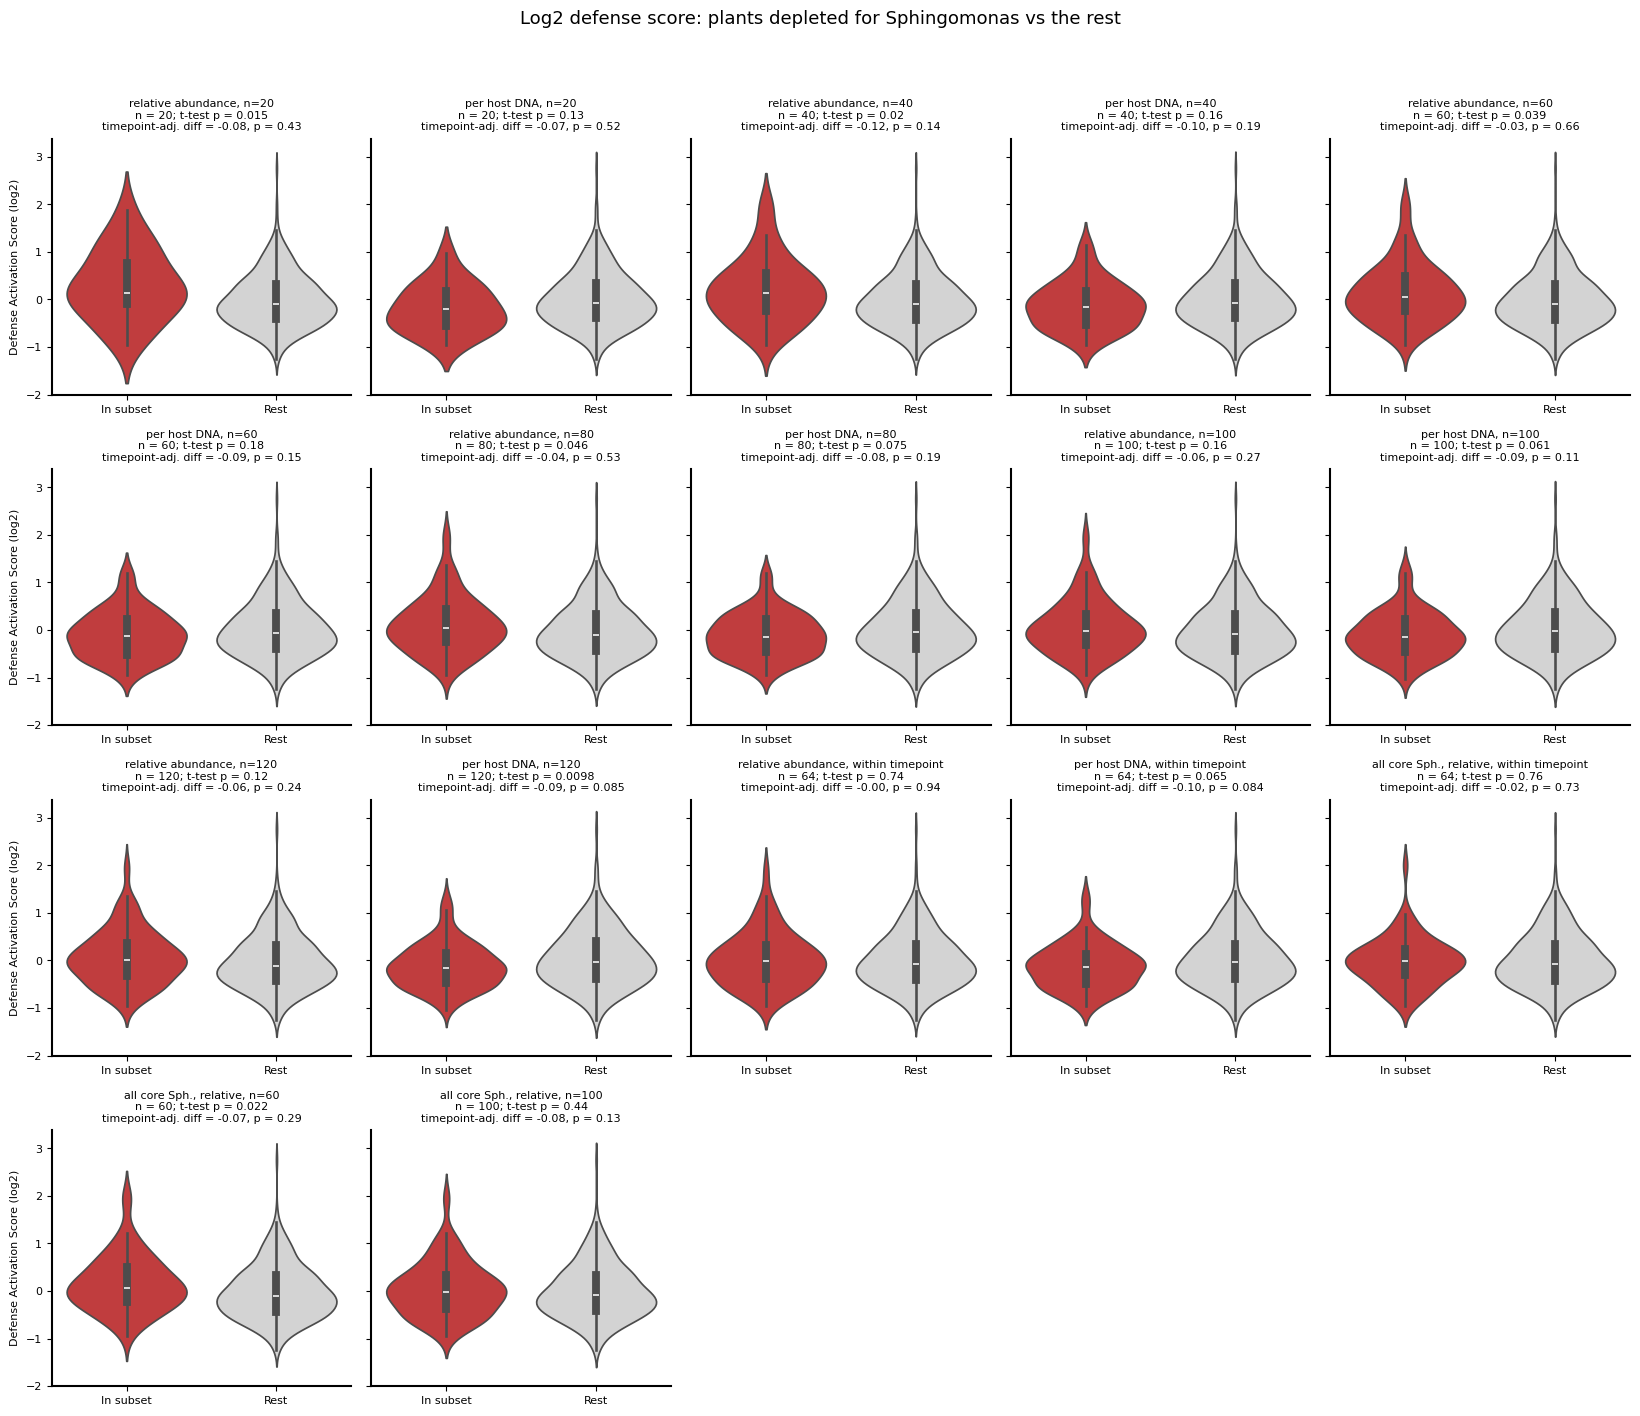

,n,t-test p,timepoint-adjusted diff,timepoint-adjusted p
"relative abundance, n=20",20.0,0.0151,-0.0840,0.4304
"per host DNA, n=20",20.0,0.1287,-0.0679,0.5206
"relative abundance, n=40",40.0,0.0203,-0.1160,0.1350
"per host DNA, n=40",40.0,0.1574,-0.0990,0.1912
"relative abundance, n=60",60.0,0.0390,-0.0282,0.6612
"per host DNA, n=60",60.0,0.1790,-0.0948,0.1488
"relative abundance, n=80",80.0,0.0458,-0.0359,0.5326
"per host DNA, n=80",80.0,0.0746,-0.0775,0.1917
"relative abundance, n=100",100.0,0.1622,-0.0585,0.2669
"per host DNA, n=100",100.0,0.0609,-0.0883,0.1083


In [17]:
sphingomonas_violin_stats = violin_grid(
    {name.replace(", absolute", "").replace("all core Sphingomonas", "all core Sph."): groups for name, (_, groups) in sphingomonas_results.items()},
    "Log2 defense score: plants depleted for Sphingomonas vs the rest",
)
sphingomonas_violin_stats.round(4)

### Depletion of each core species

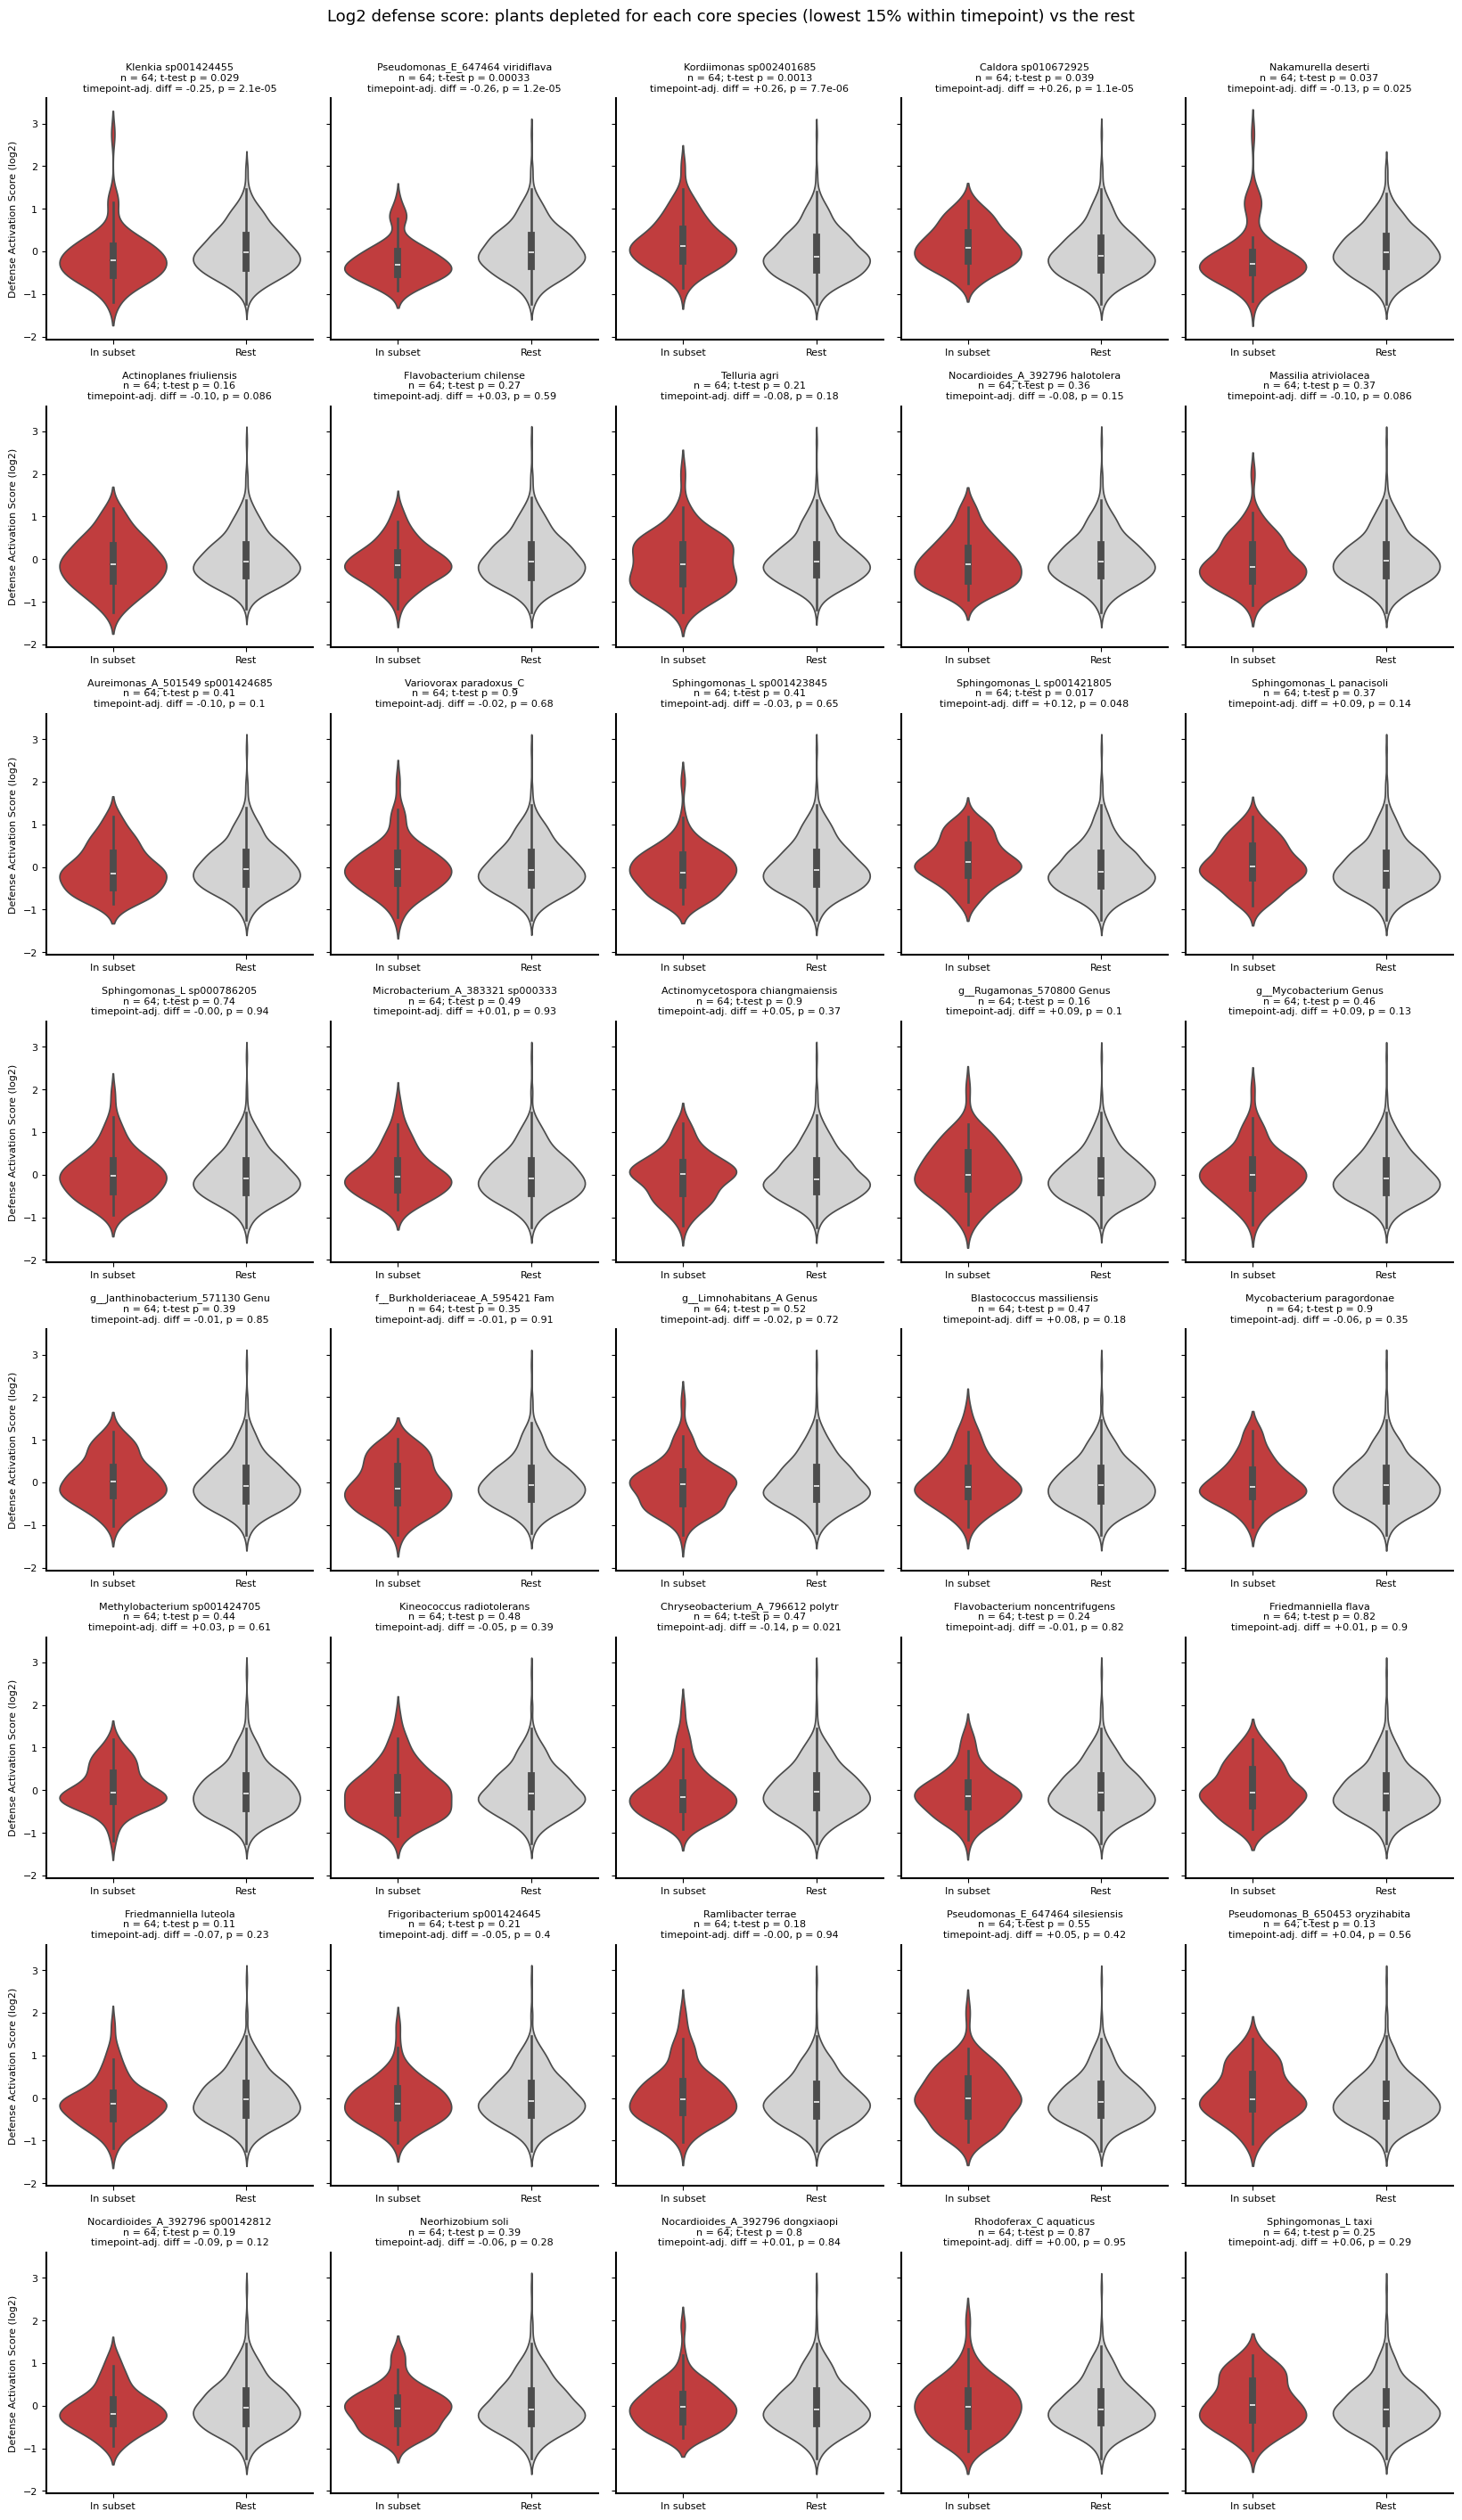

,n,t-test p,timepoint-adjusted diff,timepoint-adjusted p
Caldora sp010672925,64.0,0.0387,0.2627,0.0000
Kordiimonas sp002401685,64.0,0.0013,0.2576,0.0000
Sphingomonas_L sp001421805,64.0,0.0170,0.1179,0.0475
g__Rugamonas_570800 Genus,64.0,0.1616,0.0946,0.1043
g__Mycobacterium Genus,64.0,0.4568,0.0920,0.1346
Sphingomonas_L panacisoli,64.0,0.3685,0.0880,0.1431
Blastococcus massiliensis,64.0,0.4730,0.0824,0.1842
Sphingomonas_L taxi,64.0,0.2468,0.0621,0.2903
Actinomycetospora chiangmaiensis,64.0,0.9004,0.0528,0.3665
Pseudomonas_E_647464 silesiensis,64.0,0.5497,0.0488,0.4236


In [18]:
species_subsets = {
    species.replace("s__", "").replace("_486704", "")[:32]: lowest_within_timepoint(log_species[species])
    for species in species_depletion.sort_values("significant (padj < 0.05)", ascending=False).index
}
species_violin_stats = violin_grid(species_subsets, "Log2 defense score: plants depleted for each core species (lowest 15% within timepoint) vs the rest")
species_violin_stats.sort_values("timepoint-adjusted diff", ascending=False).round(4)

### Rare excess, 20 plants, rare = < 20% prevalence

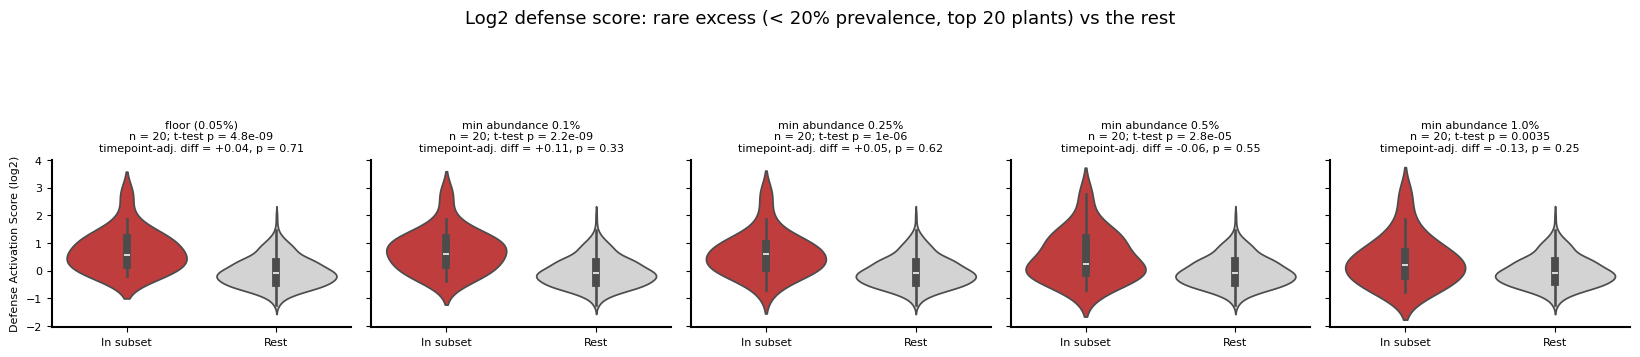

,n,t-test p,timepoint-adjusted diff,timepoint-adjusted p
floor (0.05%),20.0,0.0000,0.0409,0.7106
min abundance 0.1%,20.0,0.0000,0.1098,0.3309
min abundance 0.25%,20.0,0.0000,0.0540,0.6199
min abundance 0.5%,20.0,0.0000,-0.0650,0.5541
min abundance 1.0%,20.0,0.0035,-0.1259,0.2511


In [19]:
# Rebuild the groups exactly as in the double sweep (checked against its defense-score difference)
seasonal_matrix = species_abundance_matrix.loc[seasonal_samples]
rare_subsets = {}
for _, row in double_sweep.loc[
    (double_sweep["definition"] == "rare excess") & (double_sweep["prevalence"] == 0.2) & (double_sweep["group size"] == 20)
].iterrows():
    min_abundance = row["min abundance (%)"]
    if min_abundance == 0:
        prevalence, counted = seasonal_prevalence, sample_species
    else:
        prevalence = (seasonal_matrix >= min_abundance).mean()
        counted = sample_species.where(sample_species >= min_abundance, 0)
    rare = prevalence.index[prevalence < 0.2].intersection(counted.columns)
    high_samples = counted[rare].sum(axis=1).sort_values(ascending=False).index[:20]
    check = summarise_run(rare_results["floor (0.05%)" if min_abundance == 0 else f"min {min_abundance}%"], high_samples)
    assert abs(check["defense score diff (timepoint-adjusted)"] - row["defense score diff (timepoint-adjusted)"]) < 1e-9
    rare_subsets["floor (0.05%)" if min_abundance == 0 else f"min abundance {min_abundance}%"] = high_samples
rare_violin_stats = violin_grid(rare_subsets, "Log2 defense score: rare excess (< 20% prevalence, top 20 plants) vs the rest")
rare_violin_stats.round(4)

In [20]:
violin_stats = pd.concat(
    {"Sphingomonas": sphingomonas_violin_stats, "core species depletion": species_violin_stats, "rare excess n=20": rare_violin_stats},
    names=["family", "subset"],
)
violin_stats.to_csv(results_dir / "log2_defense_score_by_subset.csv")

## 5. *Kordiimonas* vs *Pseudomonas* depletion: opposite signals?

Hypothesis: depletion of *Kordiimonas* and depletion of *Pseudomonas* shift expression in opposite directions, and combining them into "core loss" blurs the DE signal.

1. The depletion DEs (lowest 15% within timepoint, fits from the definition screen) for *Kordiimonas* sp002401685, *P. viridiflava*, and the genus *Pseudomonas_E_647464* (10 species, mostly *P. viridiflava*).
2. Do they point in opposite directions? log2FC correlation across all genes, and direction agreement among genes significant in both.
3. How do these taxa differ between core-loss plants and the rest?

In [21]:
kordiimonas = "s__Kordiimonas sp002401685"
viridiflava = "s__Pseudomonas_E_647464 viridiflava"
caldora = "s__Caldora sp010672925"
pseudomonas_e_genus = "g__Pseudomonas_E_647464"
genus_of_species = plant_microbiome.drop_duplicates("Species").set_index("Species")["Genus"]
pseudomonas_e_abundance = sample_species.loc[:, sample_species.columns[genus_of_species.reindex(sample_species.columns) == pseudomonas_e_genus]].sum(axis=1)

opposing = {
    "Kordiimonas depleted": (species_results[kordiimonas], lowest_within_timepoint(log_species[kordiimonas])),
    "P. viridiflava depleted": (species_results[viridiflava], lowest_within_timepoint(log_species[viridiflava])),
}
genus_run_id = "".join(c if c.isalnum() else "_" for c in f"Genus depletion: {pseudomonas_e_genus}_top15").strip("_")[:120]
genus_high = lowest_within_timepoint(np.log10(pseudomonas_e_abundance + log_pseudocount))
opposing["Pseudomonas_E (genus) depleted"] = (fit_cached(screen_dir / "fits", screen_fit_id[genus_run_id], genus_high), genus_high)
assert abs(summarise_run(*opposing["Pseudomonas_E (genus) depleted"])["defense score diff (timepoint-adjusted)"] - screen_rows.loc[genus_run_id, "defense diff"]) < 1e-9

opposing_summary = pd.DataFrame(
    {
        name: {**summarise_run(results, high), **defense_gene_counts(results), **compare_to_references(results)}
        for name, (results, high) in opposing.items()
    }
).T
opposing_summary.drop(columns=["old DE genes among significant"]).round(3).T

,Kordiimonas depleted,P. viridiflava depleted,Pseudomonas_E (genus) depleted
n High,64.000,64.000,64.000
significant (padj < 0.05),411.000,480.000,330.000
up,134.000,290.000,227.000
down,277.000,190.000,103.000
"significant, |LFC| > 1",2.000,2.000,6.000
min padj,0.002,0.000,0.000
defense genes among significant,11.000,8.000,5.000
defense score diff (timepoint-adjusted),0.232,-0.211,-0.220
defense score diff p,0.000,0.000,0.000
defense genes up,10.000,0.000,0.000


In [22]:
for name, (results, _) in opposing.items():
    significant = results.loc[results["padj"] < 0.05]
    for direction, genes in [("up", significant.index[significant["log2FoldChange"] > 0]), ("down", significant.index[significant["log2FoldChange"] < 0])]:
        print(f"\n=== {name}: {direction} in depleted plants ({len(genes)} genes) ===")
        if len(genes) >= 10:
            display(go_enrichment(genes, background_genes).head(10)[["P_value", "x"]])


=== Kordiimonas depleted: up in depleted plants (134 genes) ===


,P_value,x
GO:0099503,0.105840,secretory vesicle
GO:0015145,0.105840,monosaccharide transmembrane transporter activity
GO:0009617,0.135910,response to bacterium
GO:0009751,0.470820,response to salicylic acid
GO:0042742,0.515670,defense response to bacterium
GO:0030275,0.515670,LRR domain binding
GO:0002239,0.515670,response to oomycetes
GO:0009620,0.648881,response to fungus
GO:0005886,0.648881,plasma membrane
GO:0015749,0.944953,monosaccharide transmembrane transport



=== Kordiimonas depleted: down in depleted plants (277 genes) ===


,P_value,x
GO:0009535,1.324758e-84,chloroplast thylakoid membrane
GO:0009579,9.862095e-83,thylakoid
GO:0009507,5.696157e-78,chloroplast
GO:0009941,8.252467e-72,chloroplast envelope
GO:0009534,8.406366e-66,chloroplast thylakoid
GO:0009570,1.893406e-64,chloroplast stroma
GO:0003729,2.637130e-29,mRNA binding
GO:0048046,7.039465e-22,apoplast
GO:0016168,1.529068e-18,chlorophyll binding
GO:0031977,1.180558e-14,thylakoid lumen



=== P. viridiflava depleted: up in depleted plants (290 genes) ===


,P_value,x
GO:0009535,6.510382e-103,chloroplast thylakoid membrane
GO:0009534,2.034746e-83,chloroplast thylakoid
GO:0009579,6.910324e-81,thylakoid
GO:0009507,2.770347e-67,chloroplast
GO:0009941,1.891714e-64,chloroplast envelope
GO:0009570,2.530447e-41,chloroplast stroma
GO:0003729,1.690701e-23,mRNA binding
GO:0016168,9.894095e-19,chlorophyll binding
GO:0048046,4.109117e-15,apoplast
GO:0010287,3.907343e-13,plastoglobule


... (2 outputs left out)


=== Pseudomonas_E (genus) depleted: up in depleted plants (227 genes) ===


,P_value,x
GO:0009535,5.497058e-72,chloroplast thylakoid membrane
GO:0009579,1.749452e-66,thylakoid
GO:0009534,4.497154e-66,chloroplast thylakoid
GO:0009507,5.962555e-66,chloroplast
GO:0009941,8.372447e-60,chloroplast envelope
GO:0009570,4.740085e-41,chloroplast stroma
GO:0003729,9.436055e-21,mRNA binding
GO:0048046,4.652122e-18,apoplast
GO:0010287,3.942373e-13,plastoglobule
GO:0010207,6.770562e-10,photosystem II assembly



=== Pseudomonas_E (genus) depleted: down in depleted plants (103 genes) ===


,P_value,x
GO:0099503,0.000241,secretory vesicle
GO:0009751,0.020935,response to salicylic acid
GO:0042742,0.022845,defense response to bacterium
GO:0048046,0.023166,apoplast
GO:0009414,0.023166,response to water deprivation
GO:0009505,0.028685,plant-type cell wall
GO:0002237,0.044705,response to molecule of bacterial origin
GO:0050832,0.063729,defense response to fungus
GO:0005576,0.063729,extracellular region
GO:0009409,0.076106,response to cold


log2FC Spearman, all 18032 genes: -0.27
log2FC Spearman, 773 genes significant in either: -0.67
Significant in both: 118; same direction 0, opposite 118
Plants in both depletion groups: 12 of 64 (~10 expected by chance)
Within-timepoint Spearman of Kordiimonas vs P. viridiflava log abundance: 0.08


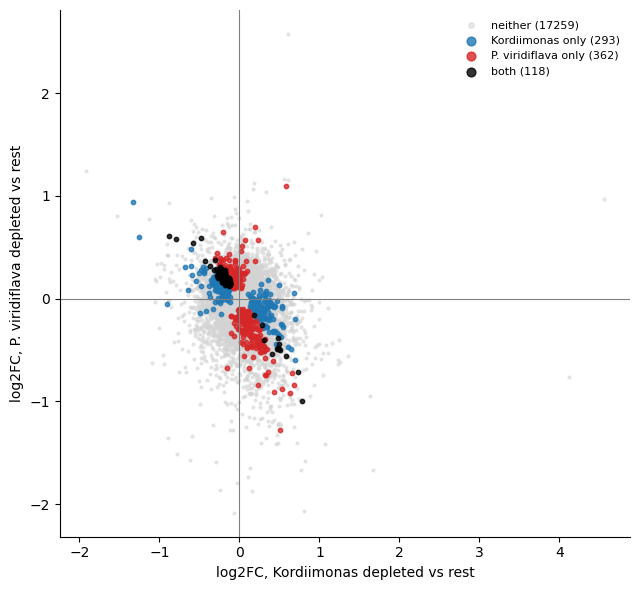

In [23]:
# Do the two depletions push expression in opposite directions?
k_results = opposing["Kordiimonas depleted"][0]
p_results = opposing["P. viridiflava depleted"][0]
shared_genes = k_results.index.intersection(p_results.index)
k_significant = set(k_results.index[k_results["padj"] < 0.05])
p_significant = set(p_results.index[p_results["padj"] < 0.05])
both = sorted(k_significant & p_significant)
either = sorted(k_significant | p_significant)
print(f"log2FC Spearman, all {len(shared_genes)} genes: {spearmanr(k_results.loc[shared_genes, 'log2FoldChange'], p_results.loc[shared_genes, 'log2FoldChange'])[0]:.2f}")
print(f"log2FC Spearman, {len(either)} genes significant in either: {spearmanr(k_results.loc[either, 'log2FoldChange'], p_results.loc[either, 'log2FoldChange'])[0]:.2f}")
same_direction = (np.sign(k_results.loc[both, "log2FoldChange"]) == np.sign(p_results.loc[both, "log2FoldChange"])).sum()
print(f"Significant in both: {len(both)}; same direction {same_direction}, opposite {len(both) - same_direction}")
print(f"Plants in both depletion groups: {len(set(opposing['Kordiimonas depleted'][1]) & set(opposing['P. viridiflava depleted'][1]))} of 64 "
      f"(~{64 * 64 / len(de_samples):.0f} expected by chance)")
print(f"Within-timepoint Spearman of Kordiimonas vs P. viridiflava log abundance: "
      f"{spearmanr(within_timepoint_z(log_species[kordiimonas]), within_timepoint_z(log_species[viridiflava]))[0]:.2f}")

fig, ax = plt.subplots(figsize=(6.5, 6))
fig.patch.set_facecolor("white")
status = pd.Series("neither", index=shared_genes)
status[status.index.isin(k_significant)] = "Kordiimonas only"
status[status.index.isin(p_significant)] = "P. viridiflava only"
status[status.index.isin(both)] = "both"
palette = {"neither": "lightgray", "Kordiimonas only": "tab:blue", "P. viridiflava only": "tab:red", "both": "black"}
for label in palette:
    genes = status.index[status == label]
    ax.scatter(k_results.loc[genes, "log2FoldChange"], p_results.loc[genes, "log2FoldChange"], s=4 if label == "neither" else 10, color=palette[label], alpha=0.5 if label == "neither" else 0.8, label=f"{label} ({len(genes)})")
ax.axhline(0, color="gray", linewidth=0.8)
ax.axvline(0, color="gray", linewidth=0.8)
ax.set_xlabel("log2FC, Kordiimonas depleted vs rest")
ax.set_ylabel("log2FC, P. viridiflava depleted vs rest")
ax.legend(frameon=False, fontsize=8, markerscale=2)
sns.despine()
plt.tight_layout()

In [24]:
# How these taxa differ between core-loss plants (absolute, n = 115) and the rest
taxa_in_core_loss = pd.DataFrame(
    {
        "core-loss plants (median %)": sample_species.loc[in_core_loss, [kordiimonas, caldora, viridiflava, target_species]].median(),
        "rest (median %)": sample_species.loc[~in_core_loss, [kordiimonas, caldora, viridiflava, target_species]].median(),
        "share of core loss (n=115)": (contribution / contribution.sum()).reindex([kordiimonas, caldora, viridiflava, target_species]),
    }
)
taxa_in_core_loss["core-loss plants in this species' depletion group"] = [
    int(pd.Index(core_loss_group).isin(lowest_within_timepoint(log_species[s])).sum()) for s in taxa_in_core_loss.index
]
taxa_in_core_loss.round(3)

,core-loss plants (median %),rest (median %),share of core loss (n=115),core-loss plants in this species' depletion group
Species,,,,
s__Kordiimonas sp002401685,2.886,2.726,0.001,15
s__Caldora sp010672925,0.218,0.183,-0.043,9
s__Pseudomonas_E_647464 viridiflava,0.626,1.384,0.189,12
s__Sphingomonas_L_486704 sp000786205,8.836,16.042,0.366,27


## 6. Defense activation score (log2) vs overall core loss

The same violins for the core-loss groups themselves (core species > 80% prevalence making up a low % of reads):
- **absolute ranking**, as in `core_loss_group_size_sweep_de.ipynb`: the `n` plants with the lowest core abundance
- **within timepoint**: the lowest 15% by within-timepoint z-score, and the lowest 2 plants per timepoint

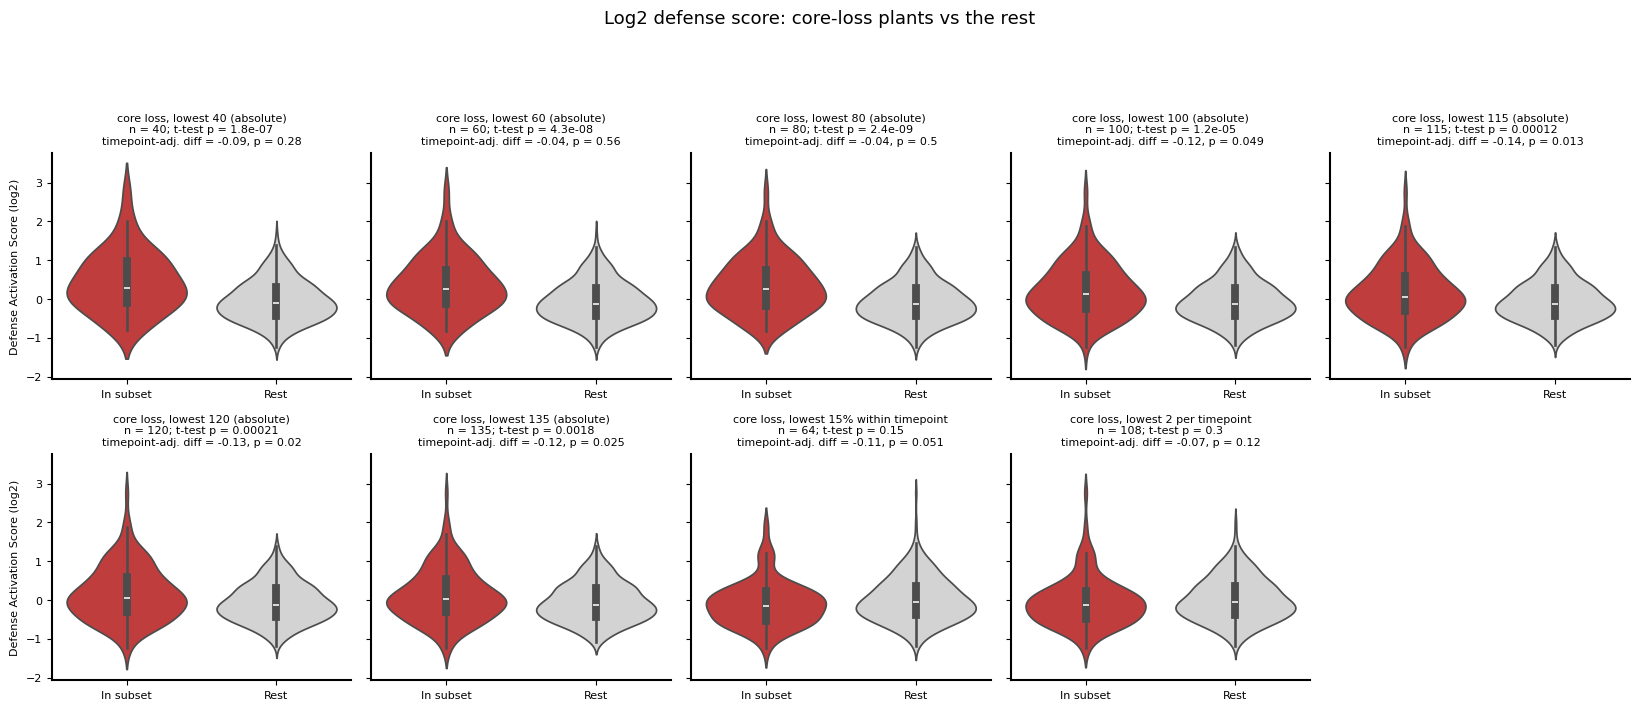

,n,t-test p,timepoint-adjusted diff,timepoint-adjusted p
"core loss, lowest 40 (absolute)",40.0,0.0000,-0.0937,0.2761
"core loss, lowest 60 (absolute)",60.0,0.0000,-0.0415,0.5611
"core loss, lowest 80 (absolute)",80.0,0.0000,-0.0446,0.4979
"core loss, lowest 100 (absolute)",100.0,0.0000,-0.1161,0.0493
"core loss, lowest 115 (absolute)",115.0,0.0001,-0.1393,0.0127
"core loss, lowest 120 (absolute)",120.0,0.0002,-0.1261,0.0205
"core loss, lowest 135 (absolute)",135.0,0.0018,-0.1153,0.0253
"core loss, lowest 15% within timepoint",64.0,0.1548,-0.1132,0.0512
"core loss, lowest 2 per timepoint",108.0,0.2951,-0.0723,0.1240


In [25]:
core_loss_subsets = {f"core loss, lowest {n} (absolute)": core_abund.sort_values().index[:n] for n in [40, 60, 80, 100, 115, 120, 135]}
core_loss_subsets["core loss, lowest 15% within timepoint"] = lowest_within_timepoint(core_abund)
core_loss_subsets["core loss, lowest 2 per timepoint"] = pd.Index(core_abund.groupby(timepoint).nsmallest(2).index.get_level_values(-1))
core_loss_violin_stats = violin_grid(core_loss_subsets, "Log2 defense score: core-loss plants vs the rest")
core_loss_violin_stats.to_csv(results_dir / "log2_defense_score_core_loss.csv")
core_loss_violin_stats.round(4)

### Core loss in the first vs second half of the timepoints

Timepoints are ordered by sampling date and split into a first and second half. Each panel compares core-loss plants with the other plants **in that half**, with the timepoint-adjusted difference computed within the half. The circadian timepoints (February–March) fall in the second half.

first half: 27 timepoints, 01 Nov 2023 to 11 Feb 2024, 215 plants
second half: 27 timepoints, 11 Feb 2024 to 14 Mar 2024, 211 plants


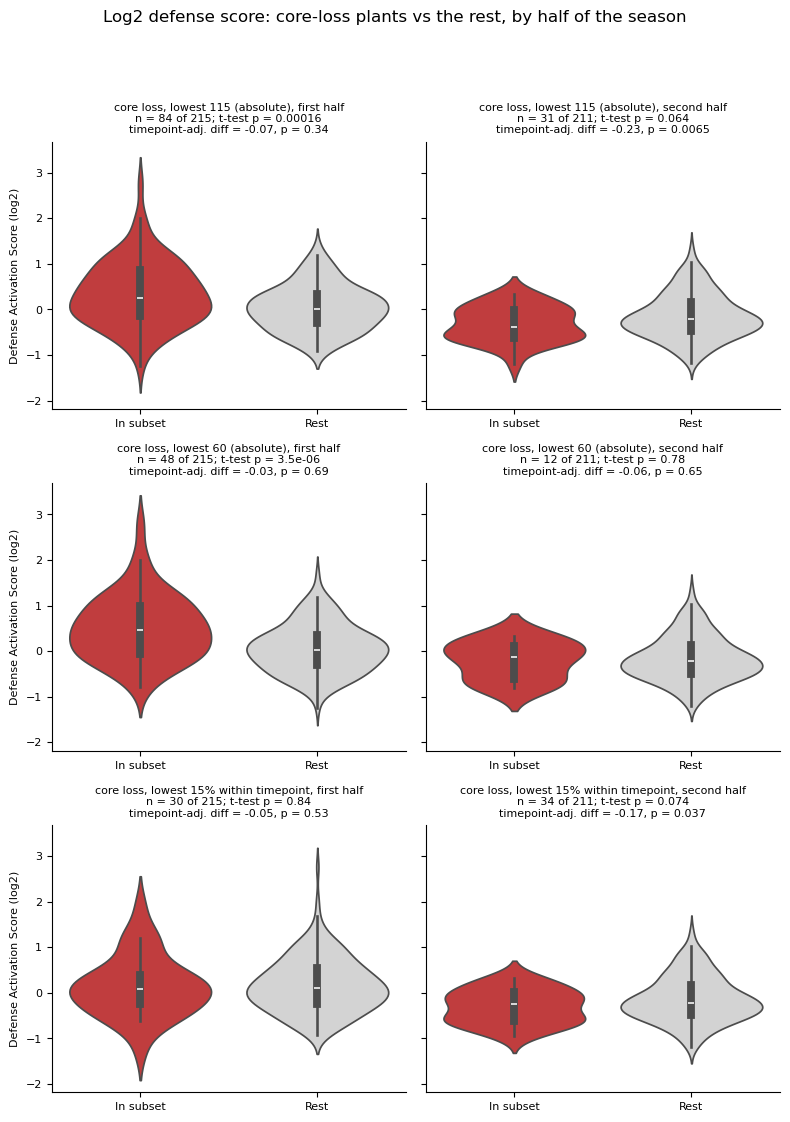

,definition,half,n in subset,n in half,t-test p,timepoint-adjusted diff,timepoint-adjusted p
0,"core loss, lowest 115 (absolute)",first half,84,215,0.0002,-0.0699,0.3424
1,"core loss, lowest 115 (absolute)",second half,31,211,0.0635,-0.2337,0.0065
2,"core loss, lowest 60 (absolute)",first half,48,215,0.0000,-0.0337,0.6907
3,"core loss, lowest 60 (absolute)",second half,12,211,0.7797,-0.0602,0.6497
4,"core loss, lowest 15% within timepoint",first half,30,215,0.8355,-0.0529,0.5314
5,"core loss, lowest 15% within timepoint",second half,34,211,0.0736,-0.1667,0.0372


In [26]:
timepoint_dates = (
    plant_microbiome.groupby("timepoint")[["day", "time"]].first()
    .pipe(lambda df: pd.to_datetime(df["day"] + " " + df["time"], format="%m/%d/%y %H:%M"))
    .loc[sorted(timepoint.unique())]
    .sort_values()
)
half_size = int(np.ceil(len(timepoint_dates) / 2))
first_half_timepoints = timepoint_dates.index[:half_size]
season_half = pd.Series(np.where(timepoint.isin(first_half_timepoints), "first half", "second half"), index=de_samples)
for half, tps in [("first half", timepoint_dates.index[:half_size]), ("second half", timepoint_dates.index[half_size:])]:
    print(f"{half}: {len(tps)} timepoints, {timepoint_dates[tps].min():%d %b %Y} to {timepoint_dates[tps].max():%d %b %Y}, "
          f"{(season_half == half).sum()} plants")

half_definitions = {
    "core loss, lowest 115 (absolute)": core_abund.sort_values().index[:115],
    "core loss, lowest 60 (absolute)": core_abund.sort_values().index[:60],
    "core loss, lowest 15% within timepoint": lowest_within_timepoint(core_abund),
}
fig, axes = plt.subplots(len(half_definitions), 2, figsize=(8, 3.8 * len(half_definitions)), sharey=True, squeeze=False)
fig.patch.set_facecolor("white")
half_rows = []
for row, (name, group) in enumerate(half_definitions.items()):
    for column, half in enumerate(["first half", "second half"]):
        ax = axes[row, column]
        members = de_samples[season_half == half]
        in_subset = members.isin(group)
        df = pd.DataFrame(
            {"score": log2_defense_score[members], "group": np.where(in_subset, "In subset", "Rest"), "timepoint": timepoint[members], "subset": in_subset.astype(float)},
            index=members,
        )
        sns.violinplot(data=df, x="group", y="score", order=["In subset", "Rest"], inner="box", palette={"In subset": "tab:red", "Rest": "lightgray"}, ax=ax)
        t_p = ttest_ind(df.loc[in_subset, "score"], df.loc[~in_subset, "score"])[1] if in_subset.sum() > 1 else np.nan
        fit = smf.ols("score ~ C(timepoint) + subset", data=df).fit()
        ax.set_title(
            f"{name}, {half}\nn = {in_subset.sum()} of {len(members)}; t-test p = {t_p:.2g}\n"
            f"timepoint-adj. diff = {fit.params['subset']:+.2f}, p = {fit.pvalues['subset']:.2g}",
            fontsize=8,
        )
        ax.set_xlabel("")
        ax.set_ylabel("Defense Activation Score (log2)" if column == 0 else "", fontsize=8)
        ax.tick_params(labelsize=8)
        sns.despine(ax=ax)
        half_rows.append({"definition": name, "half": half, "n in subset": int(in_subset.sum()), "n in half": len(members),
                          "t-test p": t_p, "timepoint-adjusted diff": fit.params["subset"], "timepoint-adjusted p": fit.pvalues["subset"]})
fig.suptitle("Log2 defense score: core-loss plants vs the rest, by half of the season", fontsize=12)
plt.tight_layout(rect=[0, 0, 1, 1 - 0.7 / fig.get_figheight()])
plt.show()
core_loss_by_half = pd.DataFrame(half_rows)
core_loss_by_half.to_csv(results_dir / "log2_defense_score_core_loss_by_half.csv", index=False)
core_loss_by_half.round(4)